# Highlighted Line Chart (one vs. many)

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Draws every series in a muted gray and highlights the one or two that matter. The reader gets the context of the whole group without a tangle of colors.

## When to use

- Show one entity in the context of many peers (your country vs. all others)
- There are too many series for a legend (more than ~6)
- The story is about one series' deviation from the pack

## Avoid when

- Every series is equally important (use small multiples)
- The highlighted series is not the point of the story

## Alternatives

- Small-multiple lines
- Spaghetti plot with interactive hover

## Design tips

- Gray lines thin (1px) and light; highlight 2px in the first palette color
- Label the highlighted series directly
- Optionally add the group median as a dark reference line

## Example

Unemployment rate of 20 regions over 15 years, highlighting one region.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(21)
years = np.arange(2010, 2025)
regions = [f"Region {i:02d}" for i in range(1, 21)]
base = 8 - 0.25 * (years - 2010) + np.where(years >= 2020, 2.5 * np.exp(-(years - 2020)), 0)
df = pd.DataFrame({r: base + rng.normal(0, 1.0) + rng.normal(0, 0.35, len(years)).cumsum()
                   for r in regions}, index=years)
df["Region 07"] = base - 0.3 * (years - 2010) + 1.8
df.iloc[:, :5]

,Region 01,Region 02,Region 03,Region 04,Region 05
2010,8.887510,10.606650,7.173487,8.009612,8.992366
2011,8.012295,9.998113,7.104591,7.665926,8.721347
2012,8.352609,10.197958,6.797714,7.884994,8.477716
2013,8.086048,10.167896,6.685743,8.133321,8.220856
2014,7.556056,9.993085,6.199372,7.457850,7.811786
2015,7.025021,9.456129,6.032794,7.618791,7.382798
2016,6.396035,9.207102,5.571000,6.765716,6.769587
2017,6.067759,8.905653,5.387076,6.258648,6.746523
2018,6.109619,8.968040,5.482207,5.947942,6.467068
2019,6.064041,8.761614,5.113337,5.736814,6.168964


### Plot

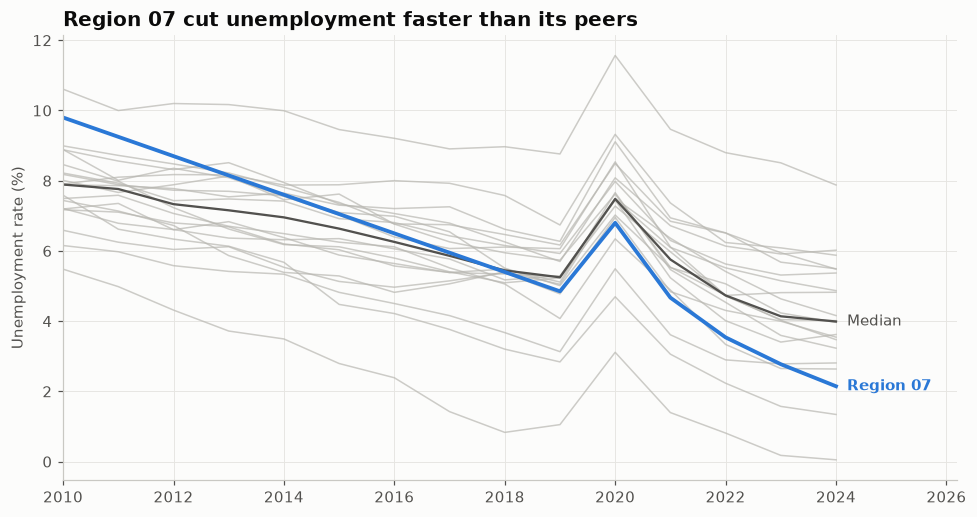

In [3]:
focus = "Region 07"
fig, ax = plt.subplots(figsize=(9, 4.8))
for col in df.columns.drop(focus):
    ax.plot(df.index, df[col], color=GRAY, linewidth=1, alpha=0.7)
ax.plot(df.index, df.median(axis=1), color="#52514e", linewidth=1.5)
ax.plot(df.index, df[focus], color=PALETTE[0], linewidth=2.5)
ax.text(df.index[-1] + 0.2, df[focus].iloc[-1], focus, color=PALETTE[0],
        va="center", fontweight="bold")
ax.text(df.index[-1] + 0.2, df.median(axis=1).iloc[-1], "Median", color="#52514e", va="center")
ax.set_xlim(df.index[0], df.index[-1] + 2.2)
ax.set_ylabel("Unemployment rate (%)")
ax.set_title("Region 07 cut unemployment faster than its peers")
fig.tight_layout()
plt.show()

## How to read it

Gray lines are the other 19 regions, the dark line is their median, and blue is the region of interest, which falls steadily below the pack.

---
Standalone script: [`line_highlight.py`](line_highlight.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)